### Cart-pole with custom static controller

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alx87grd/minilink/blob/main/examples/teaching/courses/udes_gro501/cartpole_static_controller.ipynb)


**Importing Librairies**

This page uses the toolbox *minilink*.


In [1]:
# Local: minilink already installed. Colab: clone + path.
import sys

if "google.colab" in sys.modules:
    get_ipython().run_line_magic("matplotlib", "inline")
    get_ipython().system("git clone https://github.com/alx87grd/minilink")
    sys.path.insert(0, "/content/minilink")


Cloning into 'minilink'...
remote: Enumerating objects: 30363, done.
remote: Counting objects: 100% (1585/1585), done.
remote: Compressing objects: 100% (1063/1063), done.
remote: Total 30363 (delta 1125), reused 837 (delta 519), pack-reused 28778 (from 4)
Receiving objects: 100% (30363/30363), 165.99 MiB | 19.46 MiB/s, done.
Resolving deltas: 100% (23300/23300), done.


In [2]:
import numpy as np
import scipy.linalg as linalg
import scipy.signal as signal
import matplotlib.pyplot as plt


# Defining the dynamics

Here we load a already defined class from the library including the dynamic equations of the cart-pole, which is a function of the form:

$\dot{x} = f(x,u)$


In [3]:
##############
# System
##############

from minilink import CartPole, System

sys  = CartPole()


The dynamical equations $\dot{x} = f(x,u)$ can be represented graphically by a vector field shown here:


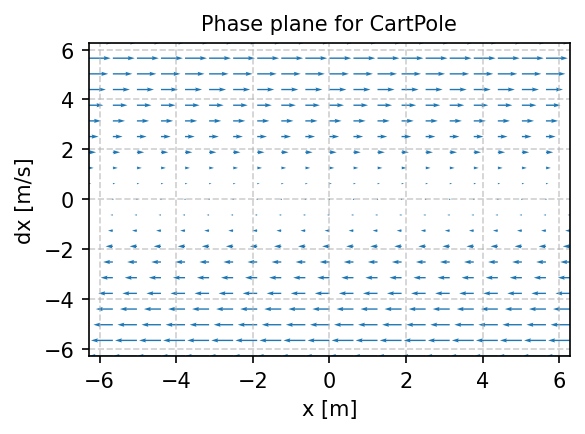

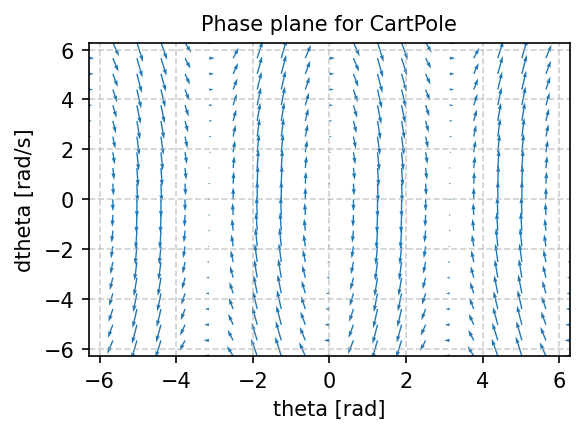

In [4]:
sys.plot_phase_plane(x_axis=0, y_axis=2) # Graphical illustration of the dynamic behavior in the phase plane
sys.plot_phase_plane(x_axis=1, y_axis=3)


Since the system has 4 states, the dynamics is actually a 4d vector field. Here we ploted 2 sub-planes of this higher dimension space.


### Showing the robot natural behavior with no controllers

Here we run a simulation of the system with no controllers:


In [5]:
# robot initial states [ joint 1 angle (rad),  joint 2 angle (rad), joint 1 velocity (rad/sec),  joint 1 velocity (rad/sec)]
sys.x0 = np.array([ 0.1, 0.1, 0.0, 0.0])

# run the simulation
sys.compute_trajectory( tf = 8 )

# Animate and display the simulation
sys.animate()



===               Time-Domain Simulation                  ===
system: 'CartPole'
n=4, m=1
x0: [0.1 0.1 0.  0. ]
interval: [0, 8]
n_pts=10001, dt=0.0008 (auto grid)
solver: 'scipy' (auto-selected)
backend='numpy'
solver_options: {'method': 'RK45', 'rtol': 0.0001, 'atol': 1e-07, 'use_jac': False}
------------------------------------------------------------
Running integration...
Completed in 0.025 seconds
------------------------------------------------------------
n_samples: 10001
x_final: [ 0.100706  0.084392 -0.011258  0.248553]
integration_stats: {'solver': 'scipy', 'mode': 'nominal', 'nfev': 470, 'njev': 0, 'nlu': 0, 'success': True, 'status': 0}


#Defining your control law


In [32]:
class CustomController( System ) :

    ############################
    def __init__( self  ):
        """ """

        super().__init__()

        # Label
        self.name = 'Custom Cart-pole Controller'

        self.add_input_port("y", dim=4)
        self.add_input_port("r", dim=1, nominal_value=0.0)
        self.add_output_port("u", dim=1, function=self.ctl, dependencies=("y",))

        # Linear Gain Matric
        m1 = 8 #kg
        m2 = 1 #kg
        g = 9.81 #N/kg
        l = 1 #m

        A = np.array([
            [0,      1,                  0,    0],
            [0,      0,           -m2*g/m1,    0],
            [0,      0,                  0,    1],
            [0,      0, ((m1+m2)*g)/(m1*l),    0]
        ])

        B = np.array([
            [0],
            [1/m1],
            [0],
            [-1/(m1*l)]
        ])

        C = np.array([
            [1,0,0,0],
            [0,0,1,0]
        ])

        D = np.array([
            [0],
            [0]
        ])

        n = A.shape[0] #Ordre du système

        # méthode placement de pôles pour synthétiser une matrice de gains
        poles_desires = np.array([-2.0, -2.5, -3.0, -3.5])

        result = signal.place_poles(A, B, poles_desires)
        self.K_poles = result.gain_matrix

        print(f"Gain à partir de la méthode de placement de pôles:\n{self.K_poles}\n")

        # méthode LQR pour synthétiser une matrice de gain optimale
        Q = np.diag([1.0, 1.0, 10.0, 1.0])       # Pénalité sur les états x'Qx
        R = np.diag([0.5])                       # Pénalité sur la commande u'Ru

        S = linalg.solve_continuous_are(A, B, Q, R)
        print(f"Solution de Riccati S :\n{S}\n")

        # TODO: Calculer des gains avec LQR!!!

        self.K = np.array([ -0.5,  25, -1.0,  5.0 ])


    #############################
    def ctl( self , x , u , t = 0, params=None ):

        y = self.get_port_values_from_u(u, "y")

        x_err = y - np.array([ 0.0, np.pi, 0.0, 0.0 ])

        u_cmd = - self.K @ x_err

        u_cmd = np.clip(u_cmd,-100.0,100.0)

        return np.array([u_cmd])

ctl = CustomController()


## Simulation

Try to play with the initial conditions:


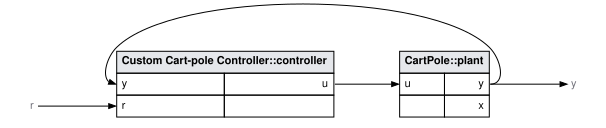

In [7]:
cl_sys = ctl @ sys

cl_sys.plot_diagram()

In [28]:
sys.x0[0] = 1.5
sys.x0[1] = 4.1

cl_sys.compute_trajectory( tf = 30.0 )


===               Time-Domain Simulation                  ===
system: 'Custom Cart-pole Controller @ CartPole'
n=4, m=1
x0: [1.5 4.1 0.  0. ]
interval: [0, 30]
n_pts=10001, dt=0.003 (auto grid)
solver: 'scipy' (auto-selected)
backend='numpy'
solver_options: {'method': 'RK45', 'rtol': 0.0001, 'atol': 1e-07, 'use_jac': False}
------------------------------------------------------------
Running integration...
Completed in 0.037 seconds
------------------------------------------------------------
n_samples: 10001
x_final: [ 1.723637e-04  3.141599e+00 -2.307463e-05 -5.728599e-06]
integration_stats: {'solver': 'scipy', 'mode': 'nominal', 'nfev': 440, 'njev': 0, 'nlu': 0, 'success': True, 'status': 0}


Trajectory, N=10001, t=0–30, x (4, 10001), u (1, 10001)

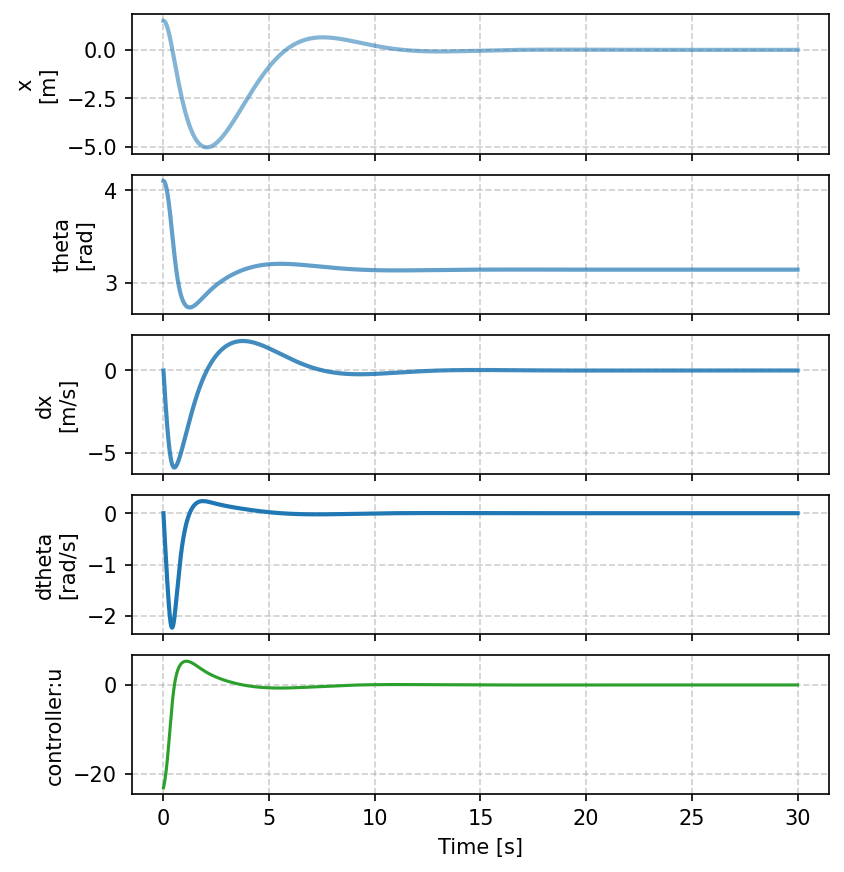

In [29]:
cl_sys.plot_trajectory()

In [30]:
# Animate and display the simulation
cl_sys.animate()
